<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 2 · Sesión 4: Pruebas de hipótesis, desbalance de clases y métricas de clasificación</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: errores tipo I/II, potencia, tests binomial/Jeffreys/HL/KS/χ², calibración vs. balanceo y punto de corte</div>
</div>

## Objetivos de la sesión (2 horas)

1. Plantear **pruebas de hipótesis** en problemas de riesgo: H0, H1, estadístico, p-valor, **errores tipo I y II** y **potencia**.
2. Aplicar los tests más usados en validación: **binomial y Jeffreys** (calibración por grado), **chi-cuadrado** (variable vs. incumplimiento), **Kolmogorov-Smirnov** y **Hosmer-Lemeshow**.
3. Calcular el **tamaño de muestra** necesario para detectar un cambio de PD.
4. Entender el **desbalance de clases** y elegir las **métricas** correctas: matriz de confusión, precisión, recall, ROC-AUC, Gini, KS, PR-AUC, Brier y log-loss.
5. Elegir un **punto de corte** según costos de negocio.

**Datos:** *Default of Credit Card Clients* (Taiwán, UCI): 30 mil tarjetahabientes, 22 % de incumplimiento, datos reales. También usamos las solicitudes tipo Home Credit (8 % de incumplimiento).

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 30 min | Lógica de las pruebas, errores y potencia |
| 2 | 30 min | Tests de validación de modelos de PD |
| 3 | 15 min | Desbalance de clases |
| 4 | 35 min | Métricas de clasificación crediticia y punto de corte |
| 5 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, brier_score_loss, log_loss, classification_report)
tw = pd.read_csv(DATA / "taiwan_default.csv")
app = pd.read_csv(DATA / "hc_application_sintetico.csv")
rng = np.random.default_rng(1)
print(tw.shape, f"tasa de incumplimiento Taiwán: {tw['default'].mean():.2%}")

(30000, 25) tasa de incumplimiento Taiwán: 22.12%


## 1. La lógica de una prueba de hipótesis

| | **H0 es verdadera** | **H0 es falsa** |
|---|---|---|
| **No rechazo H0** | ✅ Correcto (1 − α) | ❌ **Error tipo II** (β) |
| **Rechazo H0** | ❌ **Error tipo I** (α) | ✅ Correcto: **potencia** (1 − β) |

**Ejemplo de riesgo:** el modelo asigna PD = 2 % al grado A. En el año se observaron 31 incumplimientos en 1 000 clientes.
- H0: PD real del grado A = 2 % (el modelo está bien calibrado).
- H1: PD real > 2 % (el modelo **subestima** el riesgo; ésta es la dirección que preocupa al regulador).

Tasa observada: 3.10%   p-valor (binomial exacto, una cola): 0.0126
Se rechaza H0 al 5 % si se observan >= 29 incumplimientos


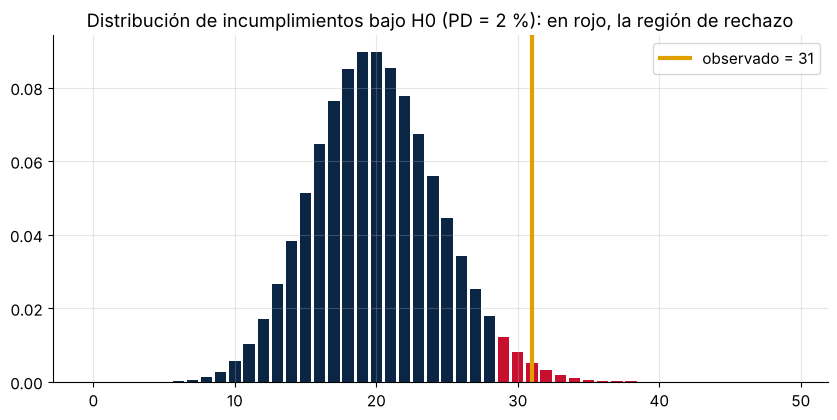

In [2]:
n, k, pd0 = 1000, 31, 0.02
res = stats.binomtest(k, n, pd0, alternative="greater")
print(f"Tasa observada: {k / n:.2%}   p-valor (binomial exacto, una cola): {res.pvalue:.4f}")
# valor crítico: ¿a partir de cuántos incumplimientos rechazamos al 5 %?
k_crit = int(stats.binom.ppf(0.95, n, pd0)) + 1
print(f"Se rechaza H0 al 5 % si se observan >= {k_crit} incumplimientos")

kk = np.arange(0, 50)
fig, ax = plt.subplots()
ax.bar(kk, stats.binom.pmf(kk, n, pd0), color=[ROJO if v >= k_crit else AZUL for v in kk])
ax.axvline(k, color=ORO, lw=3, label=f"observado = {k}")
ax.set_title("Distribución de incumplimientos bajo H0 (PD = 2 %): en rojo, la región de rechazo"); ax.legend(); plt.show()

### Potencia: ¿el test es capaz de detectar un modelo descalibrado?
Si la PD real fuera 3 % (50 % más que lo modelado), ¿con qué probabilidad lo detectaríamos? Depende de **n**.

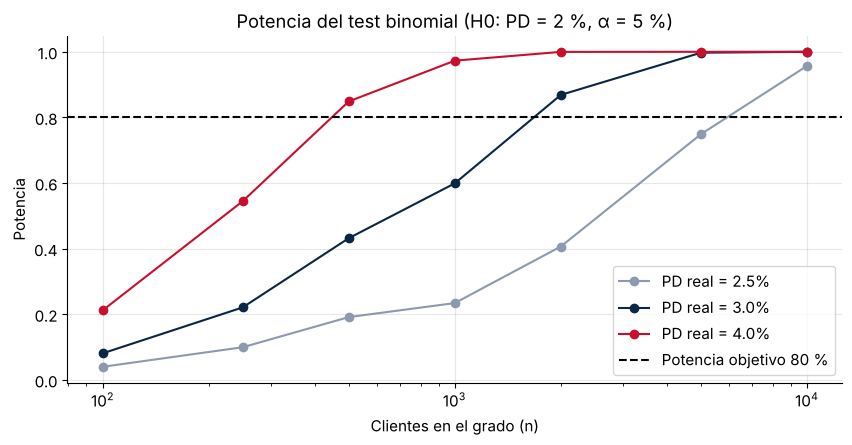

In [3]:
def potencia(n, pd0, pd1, alpha=0.05):
    kc = stats.binom.ppf(1 - alpha, n, pd0) + 1
    return 1 - stats.binom.cdf(kc - 1, n, pd1)
ns = np.array([100, 250, 500, 1000, 2000, 5000, 10000])
fig, ax = plt.subplots()
for pd1, c in [(0.025, GRIS), (0.03, AZUL), (0.04, ROJO)]:
    ax.plot(ns, [potencia(n, 0.02, pd1) for n in ns], marker="o", color=c, label=f"PD real = {pd1:.1%}")
ax.axhline(0.8, ls="--", color="black", label="Potencia objetivo 80 %"); ax.set_xscale("log")
ax.set_xlabel("Clientes en el grado (n)"); ax.set_ylabel("Potencia"); ax.legend(); ax.set_title("Potencia del test binomial (H0: PD = 2 %, α = 5 %)"); plt.show()

In [4]:
# Tamaño de muestra (aproximación normal) para detectar pd0 -> pd1 con potencia 80 %
def n_requerido(pd0, pd1, alpha=0.05, power=0.80):
    za, zb = stats.norm.ppf(1 - alpha), stats.norm.ppf(power)
    return int(np.ceil(((za * np.sqrt(pd0 * (1 - pd0)) + zb * np.sqrt(pd1 * (1 - pd1))) / (pd1 - pd0)) ** 2))
for pd1 in [0.025, 0.03, 0.04]:
    print(f"Detectar 2 % -> {pd1:.1%}: n ≈ {n_requerido(0.02, pd1):,} clientes")

Detectar 2 % -> 2.5%: n ≈ 5,233 clientes
Detectar 2 % -> 3.0%: n ≈ 1,398 clientes
Detectar 2 % -> 4.0%: n ≈ 391 clientes


**Lectura de negocio:** en carteras pequeñas o de bajo incumplimiento, un test que "no rechaza" **no prueba** que el modelo esté bien: puede simplemente carecer de potencia. Por eso en validación se combinan tests con juicio experto y benchmarks.

## 2. Tests de validación de modelos de PD
Entrenamos un modelo simple sobre Taiwán, lo agrupamos en grados de riesgo y lo validamos.

In [5]:
X = tw[["LIMIT_BAL", "AGE", "PAY_0", "PAY_2", "PAY_3", "BILL_AMT1", "PAY_AMT1", "PAY_AMT2"]].copy()
X["LIMIT_BAL"] = np.log1p(X.LIMIT_BAL); X["BILL_AMT1"] = np.sign(X.BILL_AMT1) * np.log1p(X.BILL_AMT1.abs())
X["PAY_AMT1"] = np.log1p(X.PAY_AMT1); X["PAY_AMT2"] = np.log1p(X.PAY_AMT2)
y = tw["default"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
clf = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
pte = clf.predict_proba(Xte)[:, 1]
val = pd.DataFrame({"y": yte.values, "pd": pte})
val["grado"] = pd.qcut(val.pd, 7, labels=list("ABCDEFG"))
tabla = val.groupby("grado", observed=True).agg(n=("y", "size"), defaults=("y", "sum"), pd_media=("pd", "mean"))
tabla["tasa_obs"] = tabla.defaults / tabla.n
# Test binomial (una cola, H1: PD real > PD modelo) y test de Jeffreys
tabla["p_binomial"] = [stats.binomtest(int(r.defaults), int(r.n), r.pd_media, alternative="greater").pvalue for r in tabla.itertuples()]
tabla["p_jeffreys"] = [stats.beta.cdf(r.pd_media, r.defaults + 0.5, r.n - r.defaults + 0.5) for r in tabla.itertuples()]
tabla.style.format({"pd_media": "{:.2%}", "tasa_obs": "{:.2%}", "p_binomial": "{:.4f}", "p_jeffreys": "{:.4f}"}).map(
    lambda v: "background-color:#f8d7da" if isinstance(v, float) and v < 0.05 else "", subset=["p_binomial", "p_jeffreys"])

,n,defaults,pd_media,tasa_obs,p_binomial,p_jeffreys
grado,,,,,,
A,1286,111,6.31%,8.63%,0.0007,0.0005
B,1286,191,11.09%,14.85%,0.0000,0.0000
C,1285,135,14.00%,10.51%,0.9999,0.9999
D,1286,160,16.76%,12.44%,1.0000,1.0000
E,1285,228,20.57%,17.74%,0.9950,0.9945
F,1286,433,31.12%,33.67%,0.0266,0.0248
G,1286,733,55.27%,57.00%,0.1115,0.1063


**Lectura:** los grados **A y B subestiman** el riesgo (rechazo en ambos tests), mientras que **C-E lo sobreestiman**. La causa es que el modelo trata `PAY_0` (meses de atraso: −2, −1, 0, 1, 2, …) como una variable **lineal y continua**, cuando su relación con el incumplimiento no es monótona. Es la motivación directa para la **discretización y el WoE** del Módulo 3.

El **test de Jeffreys** (usado por el BCE en el *backtesting* de PD) calcula $P(PD_{real} \le PD_{modelo} \mid \text{datos})$ con un prior Beta(½, ½): la posterior es $\text{Beta}(k + ½, n - k + ½)$. Un valor bajo indica que la PD del modelo está **por debajo** de lo que los datos sugieren.

### Hosmer-Lemeshow: calibración global
$$HL = \sum_{g=1}^{G} \frac{(O_g - E_g)^2}{E_g (1 - E_g / n_g)} \sim \chi^2_{G-2}$$

Hosmer-Lemeshow = 74.85, p-valor = 0.0000


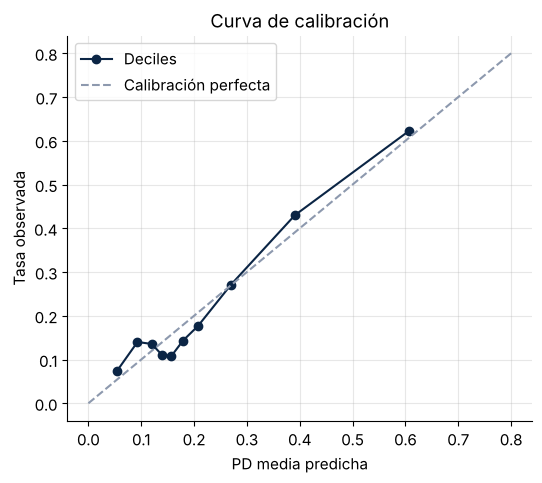

In [6]:
val["dec"] = pd.qcut(val.pd, 10, labels=False)
g = val.groupby("dec").agg(n=("y", "size"), O=("y", "sum"), E=("pd", "sum"))
HL = (((g.O - g.E) ** 2) / (g.E * (1 - g.E / g.n))).sum()
print(f"Hosmer-Lemeshow = {HL:.2f}, p-valor = {1 - stats.chi2.cdf(HL, 8):.4f}")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(g.E / g.n, g.O / g.n, "o-", color=AZUL, label="Deciles"); ax.plot([0, .8], [0, .8], "--", color=GRIS, label="Calibración perfecta")
ax.set_xlabel("PD media predicha"); ax.set_ylabel("Tasa observada"); ax.set_title("Curva de calibración"); ax.legend(); plt.show()

> **Ojo:** con muestras grandes, HL rechaza casi siempre (alta potencia frente a desviaciones pequeñas). Complementa con la curva de calibración y el juicio sobre la **materialidad** de la desviación.

### Chi-cuadrado: ¿una variable categórica está asociada al incumplimiento?

In [7]:
for col in ["EDUCATION", "MARRIAGE", "SEX"]:
    ct = pd.crosstab(tw[col], tw["default"])
    chi2, pval, dof, _ = stats.chi2_contingency(ct)
    cramer = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"{col:10s} chi2={chi2:8.1f}  gl={dof}  p={pval:.2e}  V de Cramér={cramer:.3f}")

EDUCATION  chi2=   163.2  gl=6  p=1.23e-32  V de Cramér=0.074
MARRIAGE   chi2=    35.7  gl=3  p=8.83e-08  V de Cramér=0.034
SEX        chi2=    47.7  gl=1  p=4.94e-12  V de Cramér=0.040


Con 30 mil observaciones todo sale "significativo" (p ≈ 0). La **V de Cramér** mide la **magnitud** de la asociación: aquí es pequeña. *Significativo no es lo mismo que importante.*

### Kolmogorov-Smirnov: separación entre buenos y malos
El **KS** es la máxima distancia entre las distribuciones acumuladas del score de buenos y malos. Es el estadístico de discriminación más reportado en la banca latinoamericana.

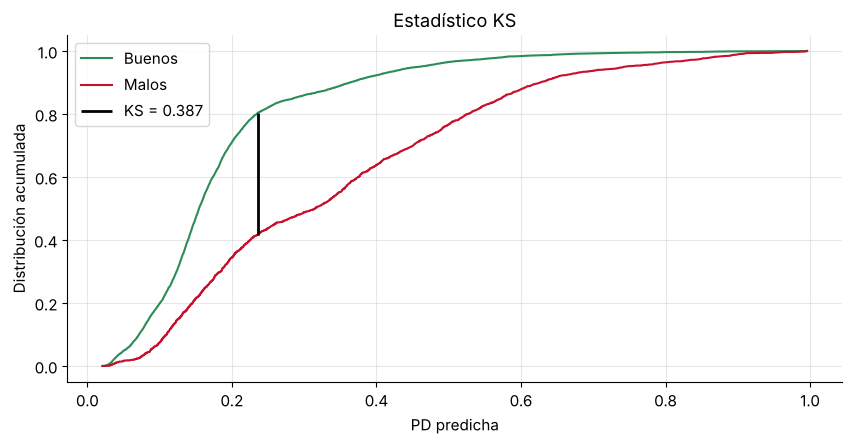

KS = 0.387, p-valor = 1.54e-208


In [8]:
ks = stats.ks_2samp(val.loc[val.y == 1, "pd"], val.loc[val.y == 0, "pd"])
s = np.sort(val.pd.unique())
cdf_b = np.searchsorted(np.sort(val.loc[val.y == 0, "pd"]), s, side="right") / (val.y == 0).sum()
cdf_m = np.searchsorted(np.sort(val.loc[val.y == 1, "pd"]), s, side="right") / (val.y == 1).sum()
i = np.argmax(cdf_b - cdf_m)
fig, ax = plt.subplots()
ax.plot(s, cdf_b, color=VERDE, label="Buenos"); ax.plot(s, cdf_m, color=ROJO, label="Malos")
ax.vlines(s[i], cdf_m[i], cdf_b[i], color="black", lw=2, label=f"KS = {ks.statistic:.3f}")
ax.set_xlabel("PD predicha"); ax.set_ylabel("Distribución acumulada"); ax.legend(); ax.set_title("Estadístico KS"); plt.show()
print(f"KS = {ks.statistic:.3f}, p-valor = {ks.pvalue:.2e}")

## 3. Desbalance de clases
En riesgo minorista la clase "mala" suele ser **minoritaria** (2-10 %). La consecuencia más común es la **paradoja de la exactitud** (*accuracy*).

In [9]:
y_hc = app.TARGET
print(f"Tasa de malos: {y_hc.mean():.2%}")
print(f"Un 'modelo' que predice 'nadie incumple' tiene una exactitud de {1 - y_hc.mean():.2%} ... y es inútil.")

Tasa de malos: 7.98%
Un 'modelo' que predice 'nadie incumple' tiene una exactitud de 92.02% ... y es inútil.


In [10]:
# Efecto del submuestreo (undersampling) y de class_weight sobre la CALIBRACIÓN
Xh = app[["EXT_SOURCE_2", "EXT_SOURCE_3", "AMT_REQ_CREDIT_BUREAU_YEAR"]].fillna(app[["EXT_SOURCE_2", "EXT_SOURCE_3"]].median()).fillna(0)
Xh["EDAD"] = -app.DAYS_BIRTH / 365.25
Xa, Xb, ya, yb = train_test_split(Xh, y_hc, test_size=0.3, random_state=0, stratify=y_hc)
m_base = LogisticRegression(max_iter=2000).fit(Xa, ya)
m_w = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xa, ya)
idx_bad = ya[ya == 1].index; idx_good = ya[ya == 0].sample(len(idx_bad), random_state=0).index
m_us = LogisticRegression(max_iter=2000).fit(Xa.loc[idx_bad.union(idx_good)], ya.loc[idx_bad.union(idx_good)])

# Corrección de prior (King & Zeng): ajusta el intercepto por la diferencia de tasas
pi_pob, pi_mues = ya.mean(), 0.5
p_us = m_us.predict_proba(Xb)[:, 1]
logit_corr = np.log(p_us / (1 - p_us)) - np.log((pi_mues / (1 - pi_mues)) / (pi_pob / (1 - pi_pob)))
p_us_corr = 1 / (1 + np.exp(-logit_corr))

comp = []
for nombre, pp in [("Base (sin balancear)", m_base.predict_proba(Xb)[:, 1]), ("class_weight='balanced'", m_w.predict_proba(Xb)[:, 1]),
                   ("Undersampling 50/50", p_us), ("Undersampling + corrección de prior", p_us_corr)]:
    comp.append({"modelo": nombre, "AUC": roc_auc_score(yb, pp), "PD media predicha": pp.mean(), "tasa real": yb.mean(),
                 "Brier": brier_score_loss(yb, pp), "LogLoss": log_loss(yb, pp)})
pd.DataFrame(comp).style.format({"AUC": "{:.4f}", "PD media predicha": "{:.2%}", "tasa real": "{:.2%}", "Brier": "{:.4f}", "LogLoss": "{:.4f}"})

,modelo,AUC,PD media predicha,tasa real,Brier,LogLoss
0,Base (sin balancear),0.7443,7.88%,7.98%,0.0682,0.2484
1,class_weight='balanced',0.7443,42.36%,7.98%,0.2037,0.5934
2,Undersampling 50/50,0.7440,42.47%,7.98%,0.2037,0.5936
3,Undersampling + corrección de prior,0.7440,7.84%,7.98%,0.0682,0.2486


**Mensaje clave:** balancear las clases **casi no cambia el AUC** (el ranking), pero **destruye la calibración**: la PD media pasa de ~8 % a ~40 %. En riesgo de crédito la PD **se usa como probabilidad** (provisiones, precio, capital), así que si balanceas, **recalibra**.

## 4. Métricas de clasificación crediticia

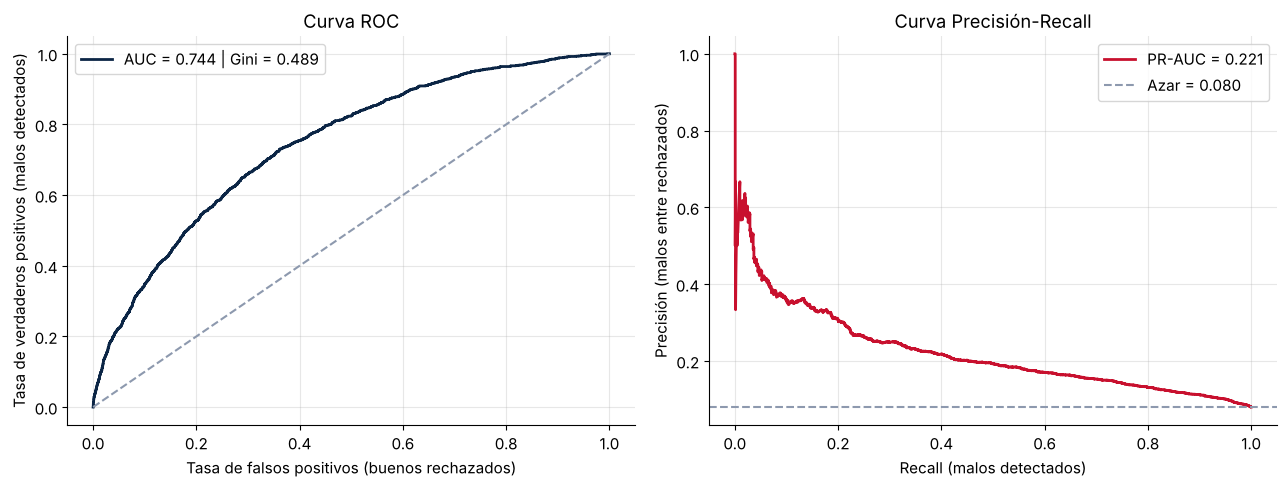

In [11]:
p_hc = m_base.predict_proba(Xb)[:, 1]
fpr, tpr, _ = roc_curve(yb, p_hc); prec, rec, _ = precision_recall_curve(yb, p_hc)
auc = roc_auc_score(yb, p_hc); ap = average_precision_score(yb, p_hc)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(fpr, tpr, color=AZUL, lw=2, label=f"AUC = {auc:.3f} | Gini = {2 * auc - 1:.3f}"); ax[0].plot([0, 1], [0, 1], "--", color=GRIS)
ax[0].set_xlabel("Tasa de falsos positivos (buenos rechazados)"); ax[0].set_ylabel("Tasa de verdaderos positivos (malos detectados)"); ax[0].set_title("Curva ROC"); ax[0].legend()
ax[1].plot(rec, prec, color=ROJO, lw=2, label=f"PR-AUC = {ap:.3f}"); ax[1].axhline(yb.mean(), ls="--", color=GRIS, label=f"Azar = {yb.mean():.3f}")
ax[1].set_xlabel("Recall (malos detectados)"); ax[1].set_ylabel("Precisión (malos entre rechazados)"); ax[1].set_title("Curva Precisión-Recall"); ax[1].legend()
plt.tight_layout(); plt.show()

| Métrica | Mide | Comentario en riesgo |
|---|---|---|
| **AUC / Gini** ($2 \cdot AUC - 1$) | Capacidad de **ordenar** | Estándar de la industria. Gini > 0.5 suele ser bueno en originación minorista |
| **KS** | Máxima separación | Muy usado en LatAm; relacionado con el punto de corte |
| **PR-AUC** | Desempeño en la clase minoritaria | Más informativo cuando la tasa de malos es muy baja |
| **Brier**, **log-loss** | **Calibración** + discriminación | Indispensables cuando la PD se usa como probabilidad |
| Precisión / Recall / F1 | Dependen del **corte** | Útiles para la política, no para comparar modelos |

### Punto de corte según costos
Un crédito malo aprobado cuesta mucho más que un bueno rechazado. Con costo de un falso negativo $C_{FN}$ (pérdida) y de un falso positivo $C_{FP}$ (margen perdido), el corte óptimo teórico para una PD calibrada es:
$$p^* = \frac{C_{FP}}{C_{FP} + C_{FN}}$$

Corte teórico p* = 0.121   |   corte empírico de mínimo costo = 0.114


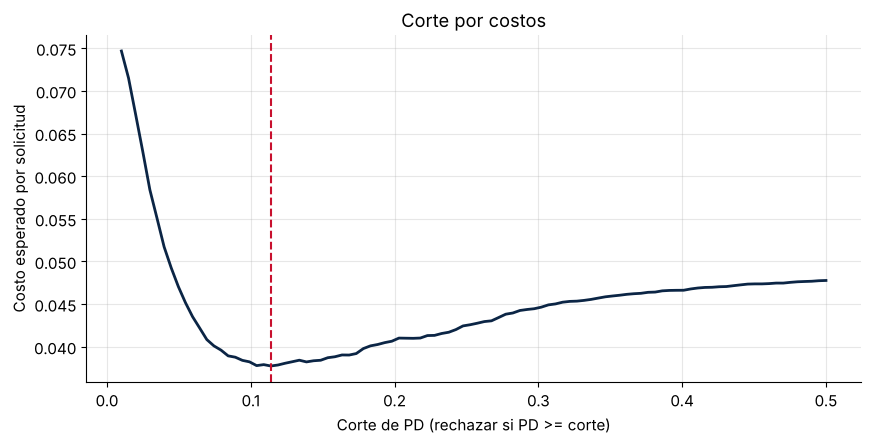

            Aprobado  Rechazado
Real bueno     13457       3123
Real malo        704        734
              precision    recall  f1-score   support

       bueno      0.950     0.812     0.876     16580
        malo      0.190     0.510     0.277      1438

    accuracy                          0.788     18018
   macro avg      0.570     0.661     0.576     18018
weighted avg      0.890     0.788     0.828     18018



In [12]:
C_FN, C_FP = 0.75 * 0.8, 0.55 * 0.15   # LGD x EAD vs. margen perdido (en proporción del monto)
cortes = np.linspace(0.01, 0.5, 100)
costo = [(C_FN * ((p_hc < c) & (yb == 1)).sum() + C_FP * ((p_hc >= c) & (yb == 0)).sum()) / len(yb) for c in cortes]
c_opt = cortes[np.argmin(costo)]
print(f"Corte teórico p* = {C_FP / (C_FP + C_FN):.3f}   |   corte empírico de mínimo costo = {c_opt:.3f}")
plt.plot(cortes, costo, color=AZUL, lw=2); plt.axvline(c_opt, color=ROJO, ls="--"); plt.xlabel("Corte de PD (rechazar si PD >= corte)"); plt.ylabel("Costo esperado por solicitud"); plt.title("Corte por costos"); plt.show()

pred = (p_hc >= c_opt).astype(int)
cm = confusion_matrix(yb, pred)
print(pd.DataFrame(cm, index=["Real bueno", "Real malo"], columns=["Aprobado", "Rechazado"]))
print(classification_report(yb, pred, target_names=["bueno", "malo"], digits=3))

## 5. Ejercicios
1. Con el grado de mayor riesgo del modelo de Taiwán, calcula la potencia de detectar un aumento de 20 % en su PD.
2. Recalcula el test de Jeffreys **por grado** usando la PD predicha + 1 pp. ¿Cuántos grados rechazan?
3. ¿Cambia el corte óptimo si el margen perdido sube a 25 %? Interprétalo en términos de **apetito de riesgo**.
4. Compara el KS y el Gini del modelo en entrenamiento vs. prueba. ¿Hay sobreajuste?

---
**Cierre del Módulo 2:** ya contamos con el lenguaje probabilístico (Bernoulli, verosimilitud, inferencia, métricas). En el **Módulo 3** lo convertiremos en una herramienta de decisión: **regresión logística y scorecards**.